In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning Models & Tools
from sklearn.model_selection import train_test_split, TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import xgboost as xgb
import lightgbm as lgb

# Time Series specific
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

In [3]:
df = pd.read_csv('../data/retail_store_inventory.csv')

In [4]:
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [5]:
print("Shape:", df.shape)

Shape: (73100, 15)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                73100 non-null  str    
 1   Store ID            73100 non-null  str    
 2   Product ID          73100 non-null  str    
 3   Category            73100 non-null  str    
 4   Region              73100 non-null  str    
 5   Inventory Level     73100 non-null  int64  
 6   Units Sold          73100 non-null  int64  
 7   Units Ordered       73100 non-null  int64  
 8   Demand Forecast     73100 non-null  float64
 9   Price               73100 non-null  float64
 10  Discount            73100 non-null  int64  
 11  Weather Condition   73100 non-null  str    
 12  Holiday/Promotion   73100 non-null  int64  
 13  Competitor Pricing  73100 non-null  float64
 14  Seasonality         73100 non-null  str    
dtypes: float64(3), int64(5), str(7)
memory usage: 8.4 MB


In [7]:
df.describe()

,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Holiday/Promotion,Competitor Pricing
count,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000,73100.000000
mean,274.469877,136.464870,110.004473,141.494720,55.135108,10.009508,0.497305,55.146077
std,129.949514,108.919406,52.277448,109.254076,26.021945,7.083746,0.499996,26.191408
min,50.000000,0.000000,20.000000,-9.990000,10.000000,0.000000,0.000000,5.030000
25%,162.000000,49.000000,65.000000,53.670000,32.650000,5.000000,0.000000,32.680000
50%,273.000000,107.000000,110.000000,113.015000,55.050000,10.000000,0.000000,55.010000
75%,387.000000,203.000000,155.000000,208.052500,77.860000,15.000000,1.000000,77.820000
max,500.000000,499.000000,200.000000,518.550000,100.000000,20.000000,1.000000,104.940000


In [8]:
df.isnull().sum()

Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Demand Forecast       0
Price                 0
Discount              0
Weather Condition     0
Holiday/Promotion     0
Competitor Pricing    0
Seasonality           0
dtype: int64

In [9]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check negative values
print("\nNegative Demand Forecast:")
print((df["Demand Forecast"] < 0).sum())

# Check negative Inventory
print("\nNegative Inventory:")
print((df["Inventory Level"] < 0).sum())

# Check negative Units Sold
print("\nNegative Units Sold:")
print((df["Units Sold"] < 0).sum())

# Check negative Units Ordered
print("\nNegative Units Ordered:")
print((df["Units Ordered"] < 0).sum())

# Check negative Price
print("\nNegative Price:")
print((df["Price"] < 0).sum())

# Check negative Discount
print("\nNegative Discount:")
print((df["Discount"] < 0).sum())

Duplicate rows: 0

Negative Demand Forecast:
673

Negative Inventory:
0

Negative Units Sold:
0

Negative Units Ordered:
0

Negative Price:
0

Negative Discount:
0


In [10]:
df["Date"] = pd.to_datetime(df["Date"])

print("Start date:", df["Date"].min())
print("End date:", df["Date"].max())
print("Number of unique dates:", df["Date"].nunique())

Start date: 2022-01-01 00:00:00
End date: 2024-01-01 00:00:00
Number of unique dates: 731


In [11]:
# Sort the data
df = df.sort_values(["Store ID", "Product ID", "Date"])

# Check rows per store-product combination
rows_per_product_store = df.groupby(
    ["Store ID", "Product ID"]
).size()

print(rows_per_product_store.describe())

count    100.0
mean     731.0
std        0.0
min      731.0
25%      731.0
50%      731.0
75%      731.0
max      731.0
dtype: float64


In [12]:
# Number of unique Store + Product combinations
print(
    "Store-Product combinations:",
    df[["Store ID", "Product ID"]].drop_duplicates().shape[0]
)

Store-Product combinations: 100


In [13]:
# Check whether each Store + Product has all 731 dates
expected_days = df["Date"].nunique()

print("Expected days per Store-Product:", expected_days)
print("Actual days per Store-Product:")
print(rows_per_product_store.value_counts().sort_index())

Expected days per Store-Product: 731
Actual days per Store-Product:
731    100
Name: count, dtype: int64


In [14]:
print(df[["Date", "Store ID", "Product ID", "Units Sold"]].head(20))

           Date Store ID Product ID  Units Sold
0    2022-01-01     S001      P0001         127
100  2022-01-02     S001      P0001          81
200  2022-01-03     S001      P0001           5
300  2022-01-04     S001      P0001          58
400  2022-01-05     S001      P0001         147
500  2022-01-06     S001      P0001          37
600  2022-01-07     S001      P0001         107
700  2022-01-08     S001      P0001           2
800  2022-01-09     S001      P0001         350
900  2022-01-10     S001      P0001          36
1000 2022-01-11     S001      P0001          16
1100 2022-01-12     S001      P0001         104
1200 2022-01-13     S001      P0001          80
1300 2022-01-14     S001      P0001         177
1400 2022-01-15     S001      P0001         176
1500 2022-01-16     S001      P0001          97
1600 2022-01-17     S001      P0001          69
1700 2022-01-18     S001      P0001         123
1800 2022-01-19     S001      P0001         211
1900 2022-01-20     S001      P0001     

In [18]:
category_sales = df.groupby("Category")["Units Sold"].sum().sort_values(
    ascending=False
)

print(category_sales)

Category
Furniture      2025017
Groceries      2000482
Clothing       1999166
Toys           1990485
Electronics    1960432
Name: Units Sold, dtype: int64


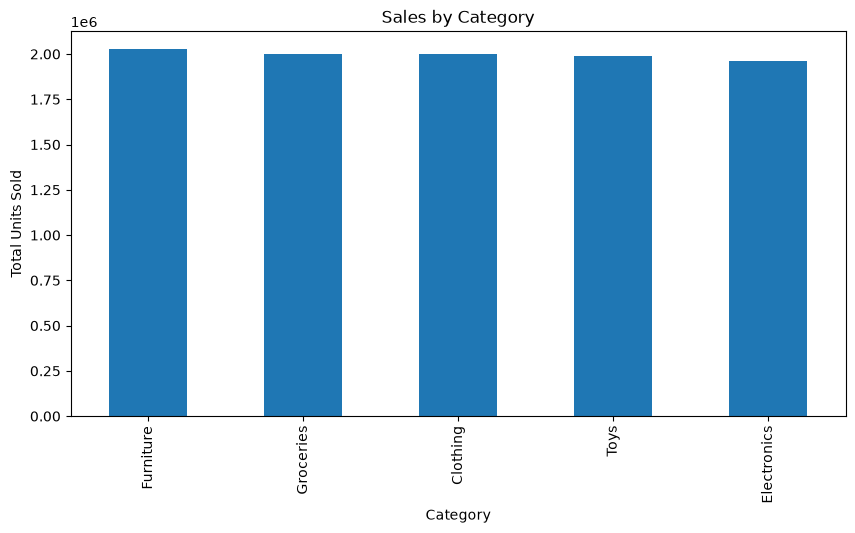

In [19]:
category_sales.plot(kind="bar", figsize=(10, 5))

plt.xlabel("Category")
plt.ylabel("Total Units Sold")
plt.title("Sales by Category")
plt.show()

In [20]:
store_sales = df.groupby("Store ID")["Units Sold"].sum().sort_values(
    ascending=False
)

print(store_sales)

Store ID
S003    2022696
S005    2010176
S002    1987715
S004    1979245
S001    1975750
Name: Units Sold, dtype: int64


In [21]:
print(
    df.groupby("Holiday/Promotion")["Units Sold"].agg(
        ["mean", "median", "sum"]
    )
)

                         mean  median      sum
Holiday/Promotion                             
0                  136.505375   107.0  5016163
1                  136.423926   108.0  4959419


In [22]:
print(
    df.groupby("Discount")["Units Sold"].mean()
)

Discount
0     135.694585
5     136.567405
10    136.769851
15    136.655293
20    136.640775
Name: Units Sold, dtype: float64


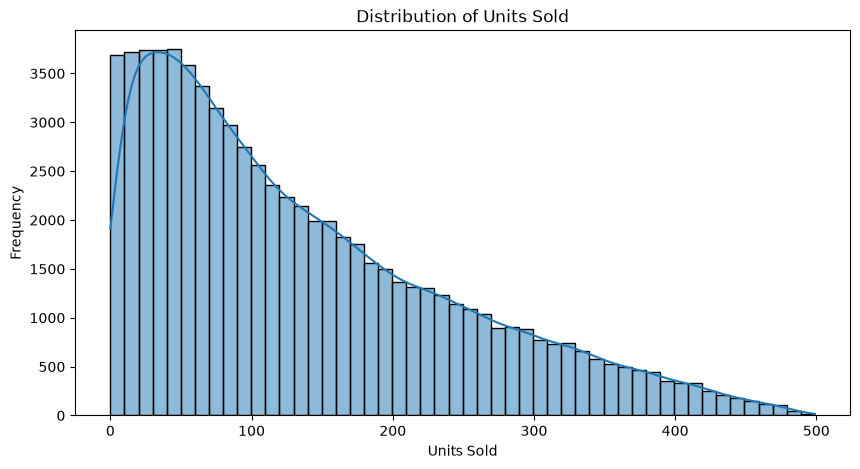

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="Units Sold", bins=50, kde=True)
plt.title("Distribution of Units Sold")
plt.xlabel("Units Sold")
plt.ylabel("Frequency")
plt.show()

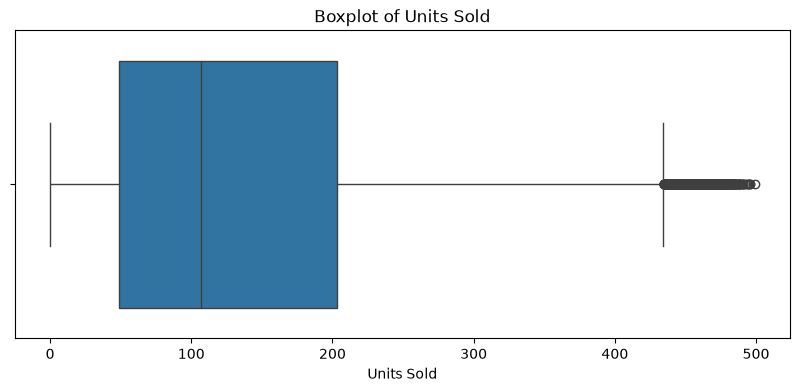

In [24]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=df["Units Sold"])
plt.title("Boxplot of Units Sold")
plt.xlabel("Units Sold")
plt.show()

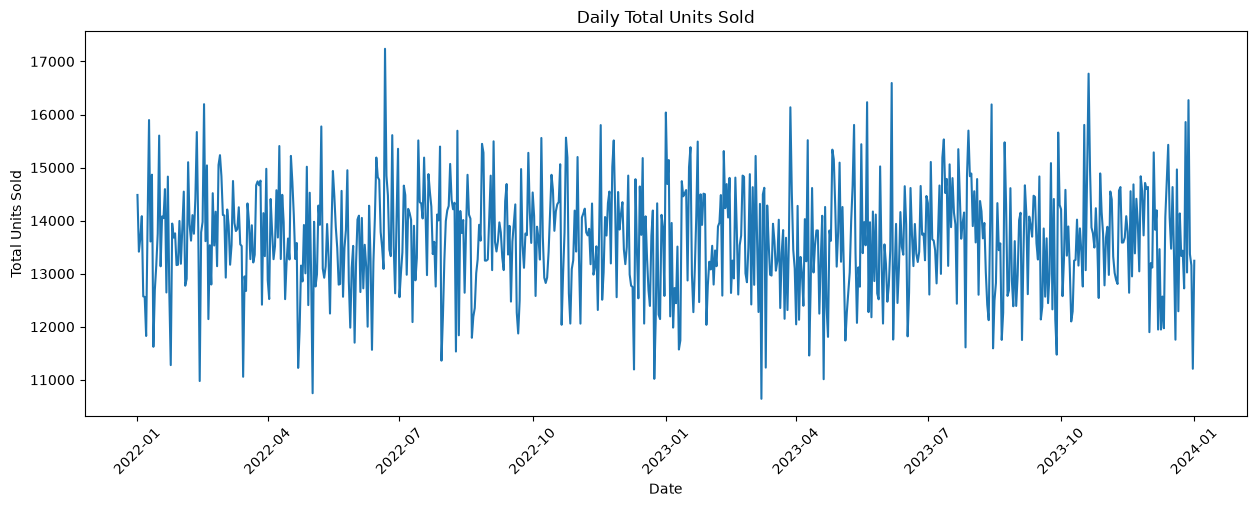

In [25]:
daily_sales = df.groupby("Date")["Units Sold"].sum().reset_index()

plt.figure(figsize=(15, 5))
sns.lineplot(data=daily_sales, x="Date", y="Units Sold")
plt.title("Daily Total Units Sold")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.show()

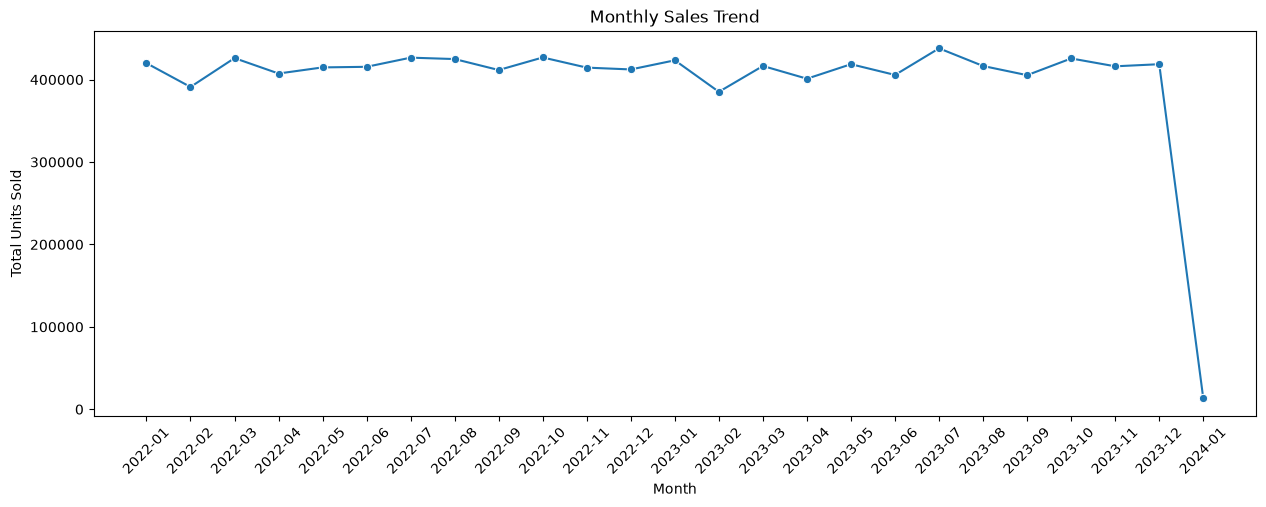

In [26]:
monthly_sales = (
    df.groupby(df["Date"].dt.to_period("M"))["Units Sold"]
    .sum()
    .reset_index()
)

monthly_sales["Date"] = monthly_sales["Date"].astype(str)

plt.figure(figsize=(15, 5))
sns.lineplot(data=monthly_sales, x="Date", y="Units Sold", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.show()

In [27]:
df["Day_of_Week"] = df["Date"].dt.day_name()

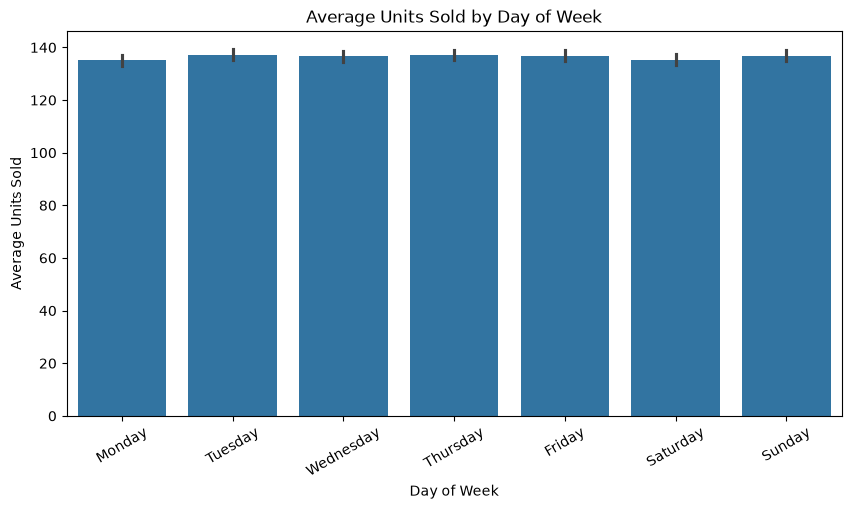

In [ ]:
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="Day_of_Week",
    y="Units Sold",
    order=day_order,
    estimator="mean"
)

plt.title("Average Units Sold by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=30)
plt.show()

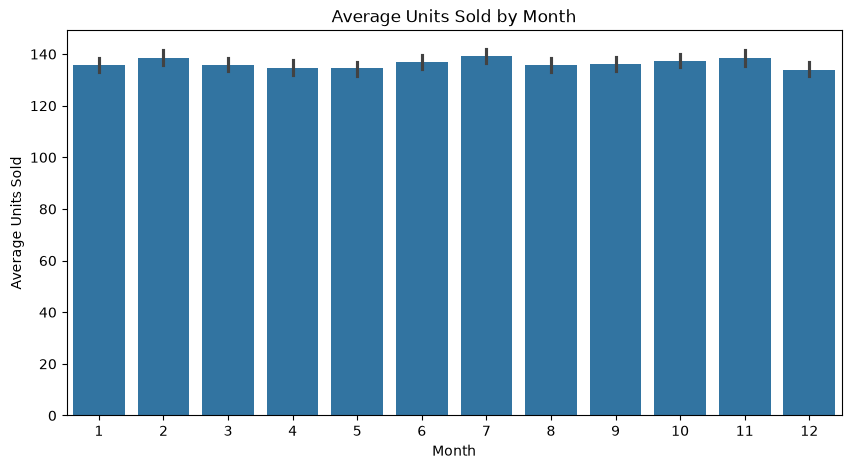

In [30]:
df["Month"] = df["Date"].dt.month

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="Month",
    y="Units Sold",
    estimator="mean"
)

plt.title("Average Units Sold by Month")
plt.xlabel("Month")
plt.ylabel("Average Units Sold")
plt.show()

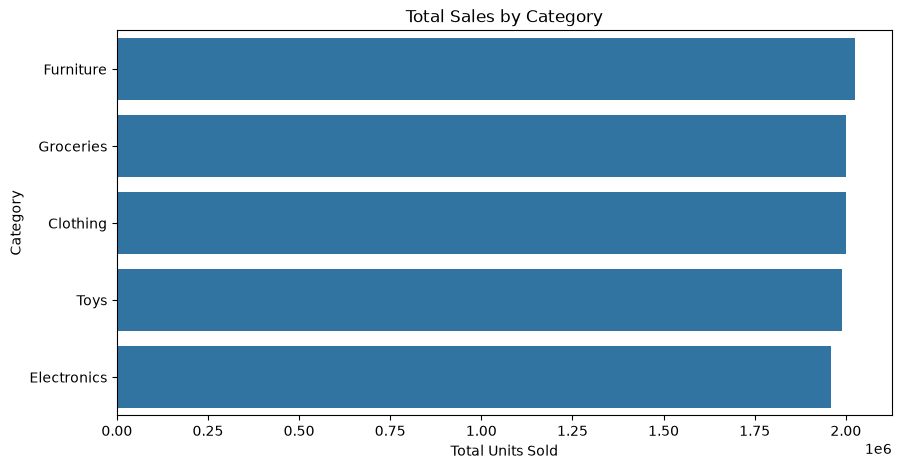

In [31]:
category_sales = (
    df.groupby("Category")["Units Sold"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_sales,
    x="Units Sold",
    y="Category"
)

plt.title("Total Sales by Category")
plt.xlabel("Total Units Sold")
plt.ylabel("Category")
plt.show()

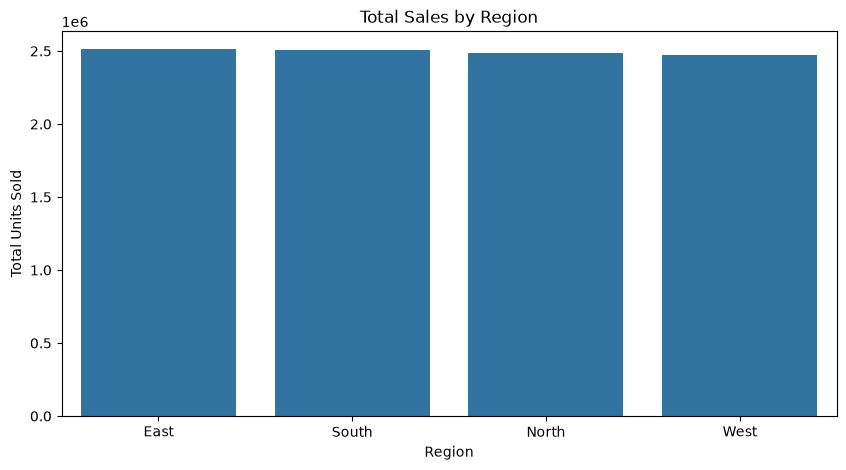

In [32]:
region_sales = (
    df.groupby("Region")["Units Sold"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=region_sales,
    x="Region",
    y="Units Sold"
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Units Sold")
plt.show()

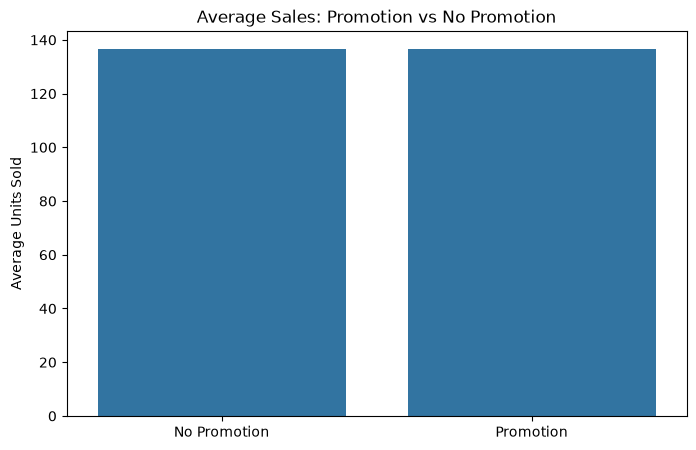

In [33]:
promotion_sales = (
    df.groupby("Holiday/Promotion")["Units Sold"]
    .mean()
    .reset_index()
)

promotion_sales["Holiday/Promotion"] = promotion_sales[
    "Holiday/Promotion"
].map({
    0: "No Promotion",
    1: "Promotion"
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=promotion_sales,
    x="Holiday/Promotion",
    y="Units Sold"
)

plt.title("Average Sales: Promotion vs No Promotion")
plt.xlabel("")
plt.ylabel("Average Units Sold")
plt.show()

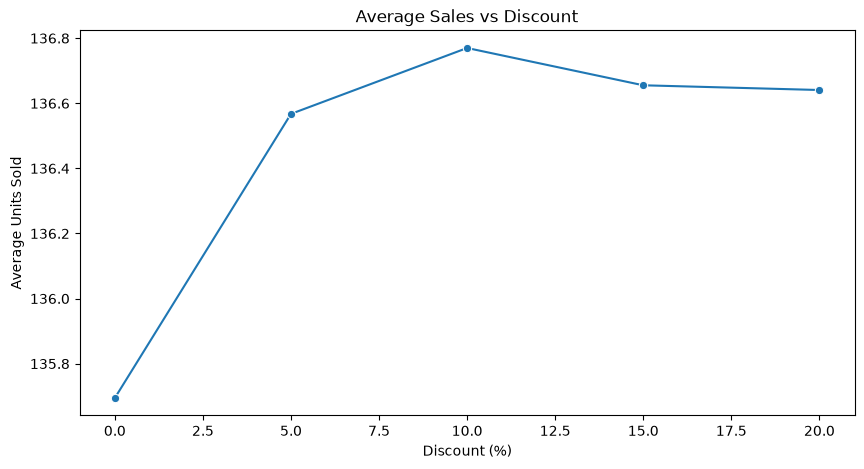

In [34]:
discount_sales = (
    df.groupby("Discount")["Units Sold"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=discount_sales,
    x="Discount",
    y="Units Sold",
    marker="o"
)

plt.title("Average Sales vs Discount")
plt.xlabel("Discount (%)")
plt.ylabel("Average Units Sold")
plt.show()

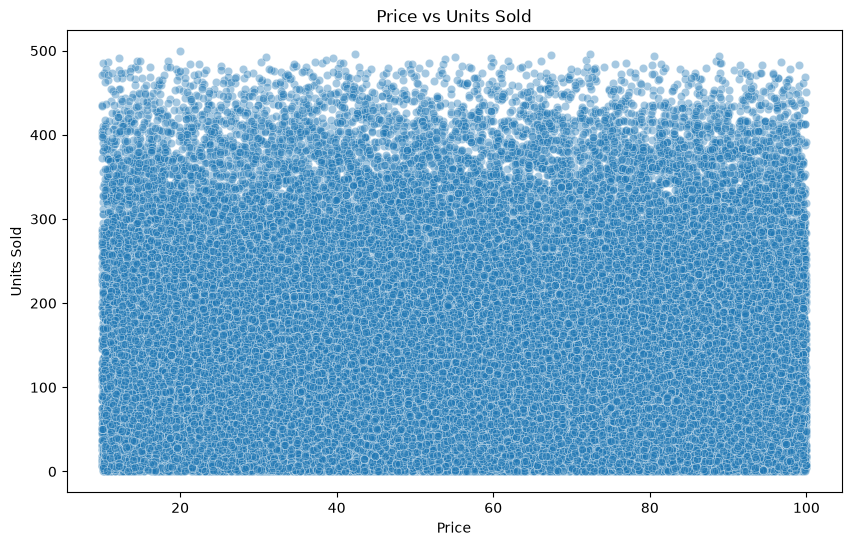

In [35]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Price",
    y="Units Sold",
    alpha=0.4
)

plt.title("Price vs Units Sold")
plt.xlabel("Price")
plt.ylabel("Units Sold")
plt.show()

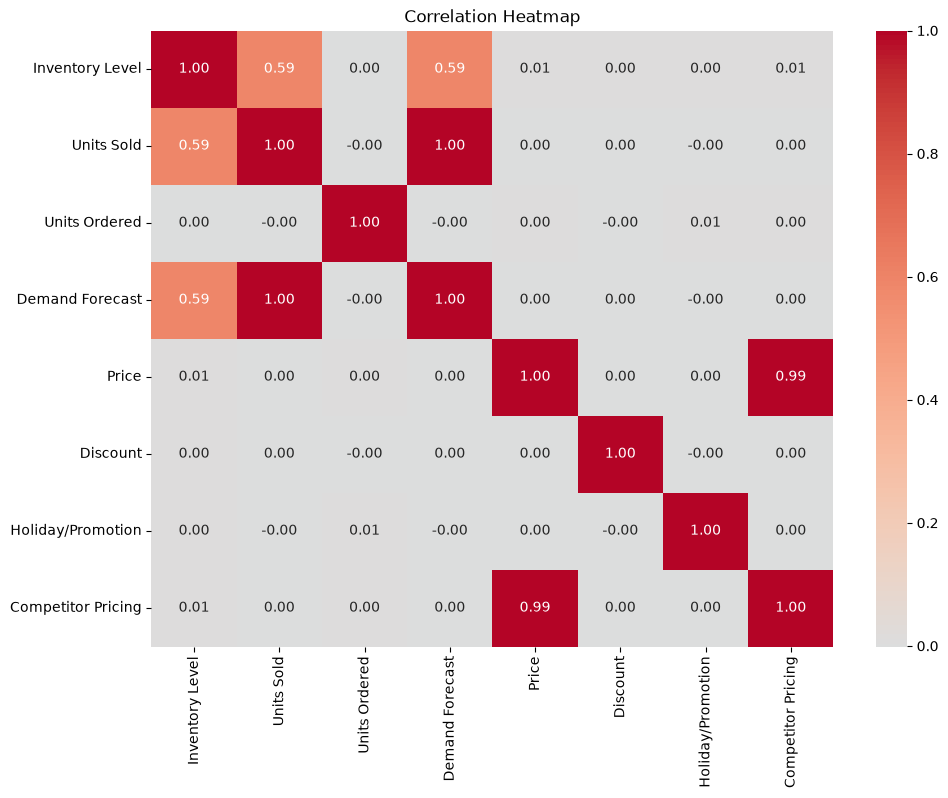

In [36]:
numeric_cols = [
    "Inventory Level",
    "Units Sold",
    "Units Ordered",
    "Demand Forecast",
    "Price",
    "Discount",
    "Holiday/Promotion",
    "Competitor Pricing"
]

correlation = df[numeric_cols].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.show()

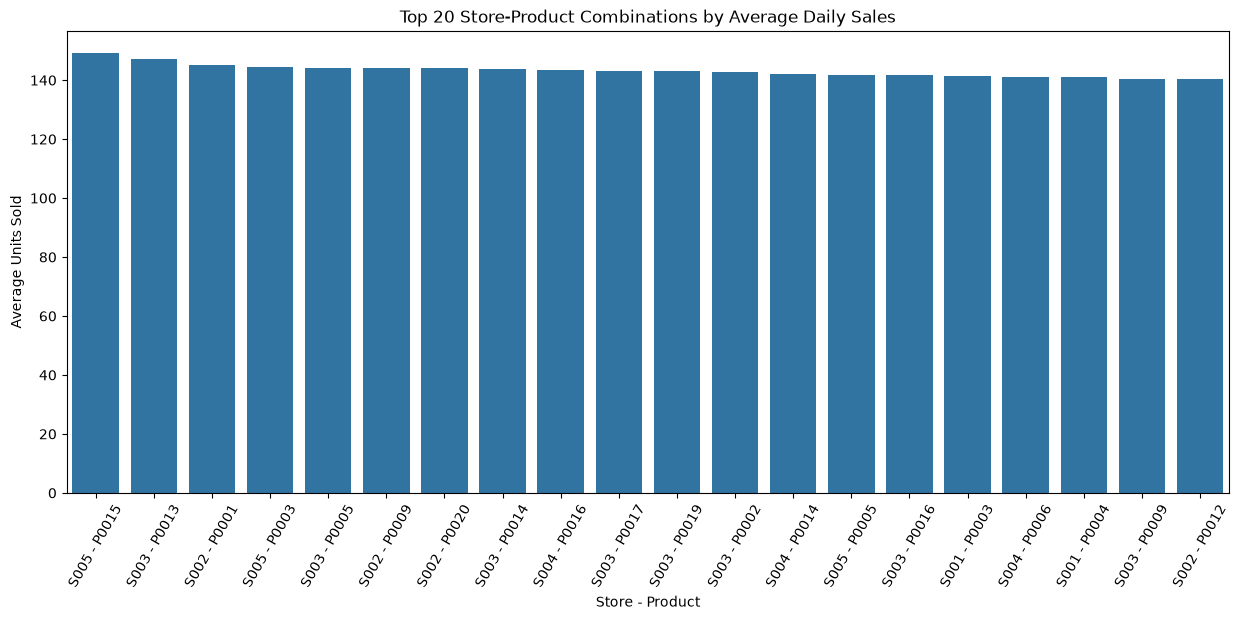

In [37]:
store_product_sales = (
    df.groupby(["Store ID", "Product ID"])["Units Sold"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

store_product_sales["Store_Product"] = (
    store_product_sales["Store ID"] + " - " +
    store_product_sales["Product ID"]
)

plt.figure(figsize=(15, 6))

sns.barplot(
    data=store_product_sales.head(20),
    x="Store_Product",
    y="Units Sold"
)

plt.title("Top 20 Store-Product Combinations by Average Daily Sales")
plt.xlabel("Store - Product")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=60)
plt.show()

In [38]:
print(df[["Price", "Competitor Pricing"]].describe())

              Price  Competitor Pricing
count  73100.000000        73100.000000
mean      55.135108           55.146077
std       26.021945           26.191408
min       10.000000            5.030000
25%       32.650000           32.680000
50%       55.050000           55.010000
75%       77.860000           77.820000
max      100.000000          104.940000


In [39]:
price_difference = df["Price"] - df["Competitor Pricing"]

print(price_difference.describe())

count    73100.000000
mean        -0.010969
std          2.888538
min         -5.000000
25%         -2.530000
50%          0.000000
75%          2.500000
max          5.000000
dtype: float64


In [40]:
df[df["Units Sold"] >= 450][
    ["Date", "Store ID", "Product ID", "Units Sold"]
].head(20)

,Date,Store ID,Product ID,Units Sold
11500,2022-04-26,S001,P0001,452
25500,2022-09-13,S001,P0001,461
58500,2023-08-09,S001,P0001,455
21901,2022-08-08,S001,P0002,486
102,2022-01-02,S001,P0003,464
16502,2022-06-15,S001,P0003,454
31502,2022-11-12,S001,P0003,479
51802,2023-06-03,S001,P0003,460
55802,2023-07-13,S001,P0003,484
63702,2023-09-30,S001,P0003,463


In [41]:
print(
    "Sales >= 450:",
    (df["Units Sold"] >= 450).sum()
)

Sales >= 450: 437


In [42]:
diff = df["Demand Forecast"] - df["Units Sold"]

print(diff.describe())
print("Exactly equal:", (diff == 0).sum())
print("Total rows:", len(df))

count    73100.000000
mean         5.029850
std          8.660766
min        -10.000000
25%         -2.470000
50%          4.990000
75%         12.510000
max         20.000000
dtype: float64
Exactly equal: 25
Total rows: 73100


In [43]:
for col in [
    "Store ID",
    "Product ID",
    "Category",
    "Region",
    "Weather Condition",
    "Seasonality"
]:
    print(f"\n{col}:")
    print(df[col].unique())


Store ID:
<StringArray>
['S001', 'S002', 'S003', 'S004', 'S005']
Length: 5, dtype: str

Product ID:
<StringArray>
['P0001', 'P0002', 'P0003', 'P0004', 'P0005', 'P0006', 'P0007', 'P0008',
 'P0009', 'P0010', 'P0011', 'P0012', 'P0013', 'P0014', 'P0015', 'P0016',
 'P0017', 'P0018', 'P0019', 'P0020']
Length: 20, dtype: str

Category:
<StringArray>
['Groceries', 'Electronics', 'Furniture', 'Toys', 'Clothing']
Length: 5, dtype: str

Region:
<StringArray>
['North', 'West', 'South', 'East']
Length: 4, dtype: str

Weather Condition:
<StringArray>
['Rainy', 'Cloudy', 'Sunny', 'Snowy']
Length: 4, dtype: str

Seasonality:
<StringArray>
['Autumn', 'Spring', 'Winter', 'Summer']
Length: 4, dtype: str


In [44]:
high_sales = df[df["Units Sold"] >= 450]

print("Number of high-sales rows:", len(high_sales))

print(
    high_sales[
        ["Date", "Store ID", "Product ID", "Units Sold"]
    ].head(20)
)

Number of high-sales rows: 437
            Date Store ID Product ID  Units Sold
11500 2022-04-26     S001      P0001         452
25500 2022-09-13     S001      P0001         461
58500 2023-08-09     S001      P0001         455
21901 2022-08-08     S001      P0002         486
102   2022-01-02     S001      P0003         464
16502 2022-06-15     S001      P0003         454
31502 2022-11-12     S001      P0003         479
51802 2023-06-03     S001      P0003         460
55802 2023-07-13     S001      P0003         484
63702 2023-09-30     S001      P0003         463
22803 2022-08-17     S001      P0004         475
25103 2022-09-09     S001      P0004         451
33603 2022-12-03     S001      P0004         458
33903 2022-12-06     S001      P0004         453
45103 2023-03-28     S001      P0004         451
52103 2023-06-06     S001      P0004         461
66003 2023-10-23     S001      P0004         470
1904  2022-01-20     S001      P0005         460
8004  2022-03-22     S001      P0005  

In [45]:
print(df[["Price", "Competitor Pricing"]].describe())

price_difference = df["Price"] - df["Competitor Pricing"]

print("\nPrice difference:")
print(price_difference.describe())

              Price  Competitor Pricing
count  73100.000000        73100.000000
mean      55.135108           55.146077
std       26.021945           26.191408
min       10.000000            5.030000
25%       32.650000           32.680000
50%       55.050000           55.010000
75%       77.860000           77.820000
max      100.000000          104.940000

Price difference:
count    73100.000000
mean        -0.010969
std          2.888538
min         -5.000000
25%         -2.530000
50%          0.000000
75%          2.500000
max          5.000000
dtype: float64


In [46]:
inventory_check = df[df["Units Sold"] > df["Inventory Level"]]

print("Rows where Units Sold > Inventory Level:", len(inventory_check))

inventory_check[
    ["Date", "Store ID", "Product ID",
     "Inventory Level", "Units Sold", "Units Ordered"]
].head(20)

Rows where Units Sold > Inventory Level: 0


,Date,Store ID,Product ID,Inventory Level,Units Sold,Units Ordered


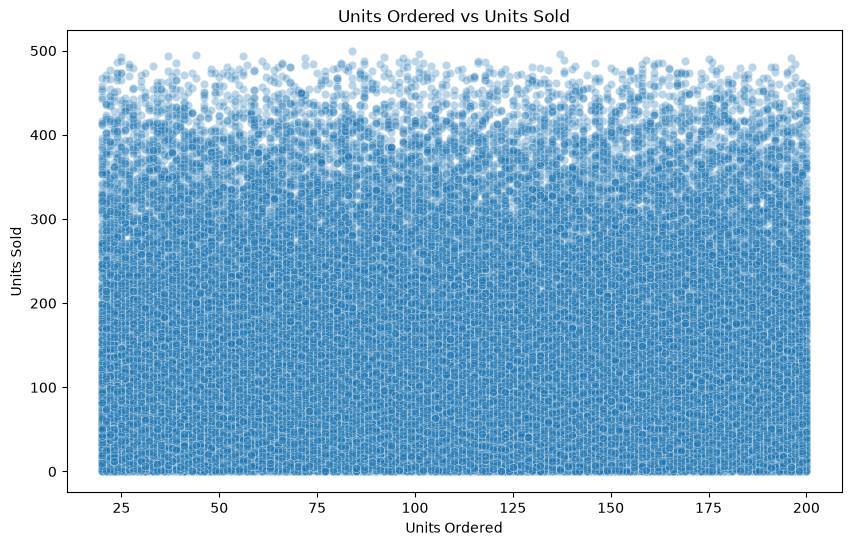

In [47]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Units Ordered",
    y="Units Sold",
    alpha=0.3
)

plt.title("Units Ordered vs Units Sold")
plt.xlabel("Units Ordered")
plt.ylabel("Units Sold")
plt.show()

In [48]:
print(
    df[["Units Ordered", "Units Sold"]].corr()
)

               Units Ordered  Units Sold
Units Ordered        1.00000    -0.00093
Units Sold          -0.00093     1.00000
